Loading plant data...
Training the AI model. Please wait...
SUCCESS! The AI predicts the plant's Efficiency within 7.67% of the real value.


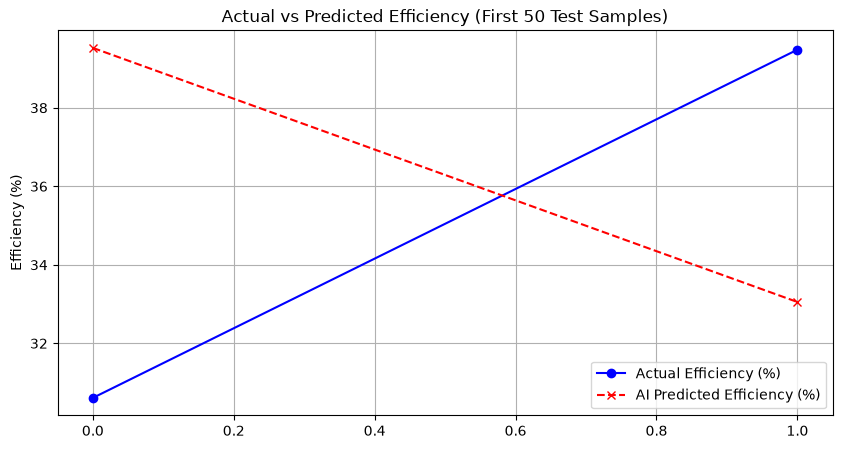

In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# 1. Load the data
print("Loading plant data...")
df = pd.read_excel('thermal_power_plant_efficiency_dataset_head_10.xlsx')

# Clean up that typo in the column name just in case (removing the r_ part)
# If your column is literally named "r_'Fuel_Type'", let me know, but it usually isn't.

# 2. Define the Sensors (X) and the Answer Key (y)
# We are ONLY selecting the columns with numbers to prevent the AI from crashing.
X = df[['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar']] 
y = df['Efficiency_%']   

# 3. Split the data (80% for learning, 20% for testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the Model
print("Training the AI model. Please wait...")
model = RandomForestRegressor(random_state=42)
model.fit(X_train, y_train)

# 5. Make predictions on the test data
predictions = model.predict(X_test)

# 6. Calculate how accurate it is
error = mean_absolute_error(y_test, predictions)
print(f"SUCCESS! The AI predicts the plant's Efficiency within {error:.2f}% of the real value.")

# 7. Plot the chart
plt.figure(figsize=(10,5))
plt.plot(y_test.values[:50], label='Actual Efficiency (%)', marker='o', color='blue')
plt.plot(predictions[:50], label='AI Predicted Efficiency (%)', marker='x', color='red', linestyle='dashed')
plt.title("Actual vs Predicted Efficiency (First 50 Test Samples)")
plt.ylabel("Efficiency (%)")
plt.legend()
plt.grid(True)
plt.show()

In [2]:
import streamlit as st
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
import warnings

# Ignore minor background warnings
warnings.filterwarnings('ignore')

# --- 1. CONFIGURE THE WEBPAGE ---
st.set_page_config(page_title="Plant AI Diagnostics", page_icon="🏭", layout="wide")

# --- 2. CACHE THE AI TRAINING ---
# This ensures the AI only trains once when the app starts, making the web app lightning fast
@st.cache_resource
def load_and_train_ai():
    try:
        # Load your synthetic dataset
        df = pd.read_csv('synthetic_plant_data.csv')
        
        # Define X and y
        X = df[['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar']]
        y = df['Fault_Code']
        
        # Train the Robot Doctor
        model = RandomForestClassifier(random_state=42)
        model.fit(X, y)
        
        return model, df
    except FileNotFoundError:
        st.error("⚠️ Error: 'synthetic_plant_data.csv' not found. Make sure it is in the same folder as this app.py file!")
        return None, None

# Load the model
doctor_model, historical_data = load_and_train_ai()

# --- 3. BUILD THE USER INTERFACE ---
if doctor_model:
    # Sidebar
    st.sidebar.title("⚙️ System Control")
    st.sidebar.info("This dashboard uses Advanced Pattern Recognition (Random Forest) to diagnose thermodynamic anomalies in real-time.")
    st.sidebar.markdown("---")
    st.sidebar.markdown("**Built for 2026 Internship Project**")

    # Main Header
    st.title("🏭 Thermal Power Plant AI Diagnostic Center")
    st.markdown("Monitor live sensors or scan historical databases for hidden mechanical degradation.")

    # Create two tabs for the app
    tab1, tab2 = st.tabs(["🎛️ Live Sensor Monitor", "📊 Database Mass Scanner"])

    # --- TAB 1: LIVE SENSOR MONITOR ---
    with tab1:
        st.subheader("Live System Input")
        st.write("Move the sliders to simulate live data coming from the plant's sensors.")
        
        # Layout columns for the sliders
        col1, col2 = st.columns(2)
        
        with col1:
            fuel = st.slider("Fuel Input Energy (GJ/hr)", min_value=50.0, max_value=250.0, value=120.0, step=1.0)
            temp = st.slider("Steam Temperature (°C)", min_value=400.0, max_value=600.0, value=540.0, step=1.0)
            
        with col2:
            press = st.slider("Steam Pressure (bar)", min_value=50.0, max_value=200.0, value=150.0, step=1.0)
            cond = st.slider("Condenser Pressure (bar)", min_value=0.01, max_value=0.30, value=0.05, step=0.01)

        # Format the slider data for the AI
        live_sensors = pd.DataFrame([[fuel, temp, press, cond]], 
                                    columns=['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar'])
        
        # Get the AI Diagnosis
        diagnosis = doctor_model.predict(live_sensors)[0]

        # Display the result in a beautiful colored box
        st.markdown("---")
        st.subheader("🤖 Real-Time AI Diagnosis")
        
        if diagnosis == 0:
            st.success("✅ **SYSTEM NORMAL:** All thermodynamic parameters are operating within expected baseline limits.")
        elif diagnosis == 1:
            st.error("🚨 **CRITICAL ANOMALY DETECTED: Boiler Tube Leak**")
            st.warning("📍 **Location:** Boiler Sub-System \n\n🔧 **Physics Pattern:** Severe steam pressure drop combined with a compensatory spike in fuel input.")
        elif diagnosis == 2:
            st.error("🚨 **CRITICAL ANOMALY DETECTED: Condenser Fouling**")
            st.warning("📍 **Location:** Cooling Sub-System \n\n🔧 **Physics Pattern:** Unexplained spike in condenser back-pressure, reducing turbine efficiency.")

    # --- TAB 2: MASS SCANNER ---
    with tab2:
        st.subheader("Automated Historical Scan")
        st.write("Click the button below to unleash the AI on the entire historical database to find hidden faults.")
        
        if st.button("🔍 Run Full Database Scan", type="primary"):
            with st.spinner("AI is analyzing thousands of sensor records..."):
                # Grab the X data
                X_historical = historical_data[['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar']]
                
                # Predict
                all_predictions = doctor_model.predict(X_historical)
                report_df = historical_data.copy()
                report_df['AI_Diagnosis'] = all_predictions
                
                # Translate
                def translate(code):
                    if code == 1: return "Boiler Leak"
                    elif code == 2: return "Condenser Fouling"
                    else: return "Normal"
                
                report_df['Diagnosis_Text'] = report_df['AI_Diagnosis'].apply(translate)
                
                # Filter to only show anomalies
                anomalies = report_df[report_df['AI_Diagnosis'] != 0]
                
                st.success(f"Scan Complete! The AI detected {len(anomalies)} anomalies out of {len(historical_data)} records.")
                
                # Display as an interactive web table
                st.dataframe(anomalies[['Steam_Pressure_bar', 'Condenser_Pressure_bar', 'Fuel_Input_Energy_GJ_per_hr', 'Diagnosis_Text']], use_container_width=True)

2026-07-21 14:34:02.119 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-21 14:34:02.147 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-21 14:34:02.854 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-21 14:34:06.019 
  command:

    streamlit run c:\Users\dell\Desktop\NTPC Project\.venv\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-07-21 14:34:06.021 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-21 14:34:06.023 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-07-21 14:34:06.025 Thr

In [3]:
# --- FAULT DETECTION SIMULATION ---

print("Simulating a Steam Valve Leak...")

# 1. We take one specific moment in time from your data
snapshot = X_test.iloc[[0]].copy()
real_efficiency = y_test.iloc[0]

# 2. The AI looks at the temperature and pressure and predicts what efficiency SHOULD be
expected_efficiency = model.predict(snapshot)[0]

# 3. WE INJECT A FAULT: We pretend a valve broke, causing actual efficiency to drop by 6% 
# while the temperature and pressure sensors stayed the same.
broken_sensor_efficiency = real_efficiency - 6.0 

print(f"-> AI Expected Efficiency: {expected_efficiency:.2f}%")
print(f"-> Actual Sensor Reading:  {broken_sensor_efficiency:.2f}%")

# 4. The Logic: If the gap between expectation and reality is too big, sound the alarm!
efficiency_gap = expected_efficiency - broken_sensor_efficiency

print("-" * 30)
if efficiency_gap > 3.0: # Our threshold is 3%
    print(f"🚨 ALARM TRIGGERED! Unexplained efficiency drop of {efficiency_gap:.2f}%!")
    print("🚨 DIAGNOSIS: Possible steam leak, boiler fouling, or mechanical degradation.")
else:
    print("✅ System Normal. Plant is operating at expected efficiency.")

Simulating a Steam Valve Leak...
-> AI Expected Efficiency: 39.53%
-> Actual Sensor Reading:  24.61%
------------------------------
🚨 ALARM TRIGGERED! Unexplained efficiency drop of 14.92%!
🚨 DIAGNOSIS: Possible steam leak, boiler fouling, or mechanical degradation.


In [4]:
import pandas as pd
import numpy as np

# --- 1. SET YOUR NORMAL BASELINES ---
# Look at your 10 real entries and put the average values here:
BASE_FUEL = 120.0       # Average Fuel_Input_Energy_GJ_per_hr
BASE_STEAM_TEMP = 540.0 # Average Steam_Temperature_C
BASE_STEAM_PRESS = 150.0 # Average Steam_Pressure_bar
BASE_COND_PRESS = 0.05   # Average Condenser_Pressure_bar

# How many rows of data do you want to fake?
NUM_SAMPLES_PER_STATE = 500 

np.random.seed(42) # Keeps the random numbers the same every time you run it
data = []

print("Generating synthetic plant data...")

# --- 2. GENERATE NORMAL DATA (Label 0) ---
for _ in range(NUM_SAMPLES_PER_STATE):
    # normal(baseline, wiggle_room)
    fuel = np.random.normal(BASE_FUEL, 3.0) 
    temp = np.random.normal(BASE_STEAM_TEMP, 2.0)
    press = np.random.normal(BASE_STEAM_PRESS, 2.0)
    cond = np.random.normal(BASE_COND_PRESS, 0.005)
    data.append([fuel, temp, press, cond, 0]) # 0 = Normal

# --- 3. GENERATE BOILER TUBE LEAK (Label 1) ---
# Physics: Pressure drops heavily, Fuel spikes to compensate, Temp drops slightly
for _ in range(NUM_SAMPLES_PER_STATE):
    fuel = np.random.normal(BASE_FUEL + 35.0, 5.0)     # Fuel spikes UP
    temp = np.random.normal(BASE_STEAM_TEMP - 15.0, 3.0) # Temp drops DOWN
    press = np.random.normal(BASE_STEAM_PRESS - 40.0, 4.0) # Pressure drops heavily DOWN
    cond = np.random.normal(BASE_COND_PRESS, 0.005)      # Condenser stays normal
    data.append([fuel, temp, press, cond, 1]) # 1 = Boiler Leak

# --- 4. GENERATE CONDENSER FOULING (Label 2) ---
# Physics: Condenser pressure spikes, everything else is relatively normal but strained
for _ in range(NUM_SAMPLES_PER_STATE):
    fuel = np.random.normal(BASE_FUEL + 5.0, 2.0) 
    temp = np.random.normal(BASE_STEAM_TEMP, 2.0)
    press = np.random.normal(BASE_STEAM_PRESS, 2.0)
    cond = np.random.normal(BASE_COND_PRESS + 0.15, 0.02) # Condenser pressure spikes UP
    data.append([fuel, temp, press, cond, 2]) # 2 = Condenser Fouling

# --- 5. SAVE TO EXCEL/CSV ---
columns = ['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar', 'Fault_Code']
df = pd.DataFrame(data, columns=columns)

# Shuffle the data so it isn't perfectly in order
df = df.sample(frac=1).reset_index(drop=True)

# Save it to your folder!
df.to_csv('synthetic_plant_data.csv', index=False)
print("SUCCESS! Created 'synthetic_plant_data.csv' with 1500 rows.")

Generating synthetic plant data...
SUCCESS! Created 'synthetic_plant_data.csv' with 1500 rows.


In [5]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# 1. Load the Synthetic "Flight Simulator" Data you just generated
df = pd.read_csv('synthetic_plant_data.csv')

# 2. Separate the Sensors (X) and the categorical Answer Key (y)
X = df[['Fuel_Input_Energy_GJ_per_hr', 'Steam_Temperature_C', 'Steam_Pressure_bar', 'Condenser_Pressure_bar']]
y = df['Fault_Code'] 

# 3. Split the data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 4. Train the "Robot Doctor" AI
print("Training the Diagnostic AI on the simulated data...")
doctor_model = RandomForestClassifier(random_state=42)
doctor_model.fit(X_train, y_train)

# 5. Test the Doctor's Accuracy
predictions = doctor_model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print(f"Doctor AI trained successfully! Accuracy: {accuracy * 100:.2f}%\n")

# --- MASS ANOMALY SCANNER (UPDATED WITH LOCATIONS) ---
print("\nInitiating Mass AI Scan on all test data...")

# 1. Ask the AI to diagnose ALL the test data simultaneously
all_predictions = doctor_model.predict(X_test)

# 2. Create a copy of the test data so we can attach the AI's notes
report_df = X_test.copy()
report_df['AI_Diagnosis_Code'] = all_predictions

# 3. UPGRADED TRANSLATION: Mapping codes to Faults AND Locations
def translate_diagnosis(code):
    if code == 1:
        return "FAULT: Boiler Tube Leak | LOCATION: Boiler Sub-System"
    elif code == 2:
        return "FAULT: Condenser Fouling | LOCATION: Cooling Sub-System"
    elif code == 3:
        return "FAULT: Burner Degradation | LOCATION: Furnace Sub-System"
    else:
        return "System Normal"

# Apply the translation to a new column
report_df['Maintenance_Action'] = report_df['AI_Diagnosis_Code'].apply(translate_diagnosis)

# 4. FILTERING: Remove the normal data to focus on the broken components
anomalies_only = report_df[report_df['AI_Diagnosis_Code'] != 0]

# 5. Print a professional Final Report
print("=" * 80)
print(f"AUTOMATED DIAGNOSTIC SCAN COMPLETE.")
print(f"Processed {len(report_df)} total sensor readings.")
print(f"🚨 DETECTED {len(anomalies_only)} CRITICAL ANOMALIES 🚨")
print("=" * 80)
print("\n--- MAINTENANCE ACTION LOG (Showing first 10 identified faults) ---\n")

# We use pandas to display just the sensors that matter and the final action required
columns_to_show = ['Steam_Pressure_bar', 'Condenser_Pressure_bar', 'Fuel_Input_Energy_GJ_per_hr', 'Maintenance_Action']
display(anomalies_only[columns_to_show].head(10))

Training the Diagnostic AI on the simulated data...
Doctor AI trained successfully! Accuracy: 100.00%


Initiating Mass AI Scan on all test data...
AUTOMATED DIAGNOSTIC SCAN COMPLETE.
Processed 300 total sensor readings.
🚨 DETECTED 190 CRITICAL ANOMALIES 🚨

--- MAINTENANCE ACTION LOG (Showing first 10 identified faults) ---



,Steam_Pressure_bar,Condenser_Pressure_bar,Fuel_Input_Energy_GJ_per_hr,Maintenance_Action
1116,148.308654,0.199718,124.683389,FAULT: Condenser Fouling | LOCATION: Cooling S...
422,109.625455,0.056629,160.413455,FAULT: Boiler Tube Leak | LOCATION: Boiler Sub...
413,152.489130,0.244630,127.454069,FAULT: Condenser Fouling | LOCATION: Cooling S...
451,147.622073,0.199002,128.185340,FAULT: Condenser Fouling | LOCATION: Cooling S...
861,117.202045,0.056195,139.902439,FAULT: Boiler Tube Leak | LOCATION: Boiler Sub...
1063,148.962667,0.217064,126.140842,FAULT: Condenser Fouling | LOCATION: Cooling S...
1272,112.488280,0.056645,160.408834,FAULT: Boiler Tube Leak | LOCATION: Boiler Sub...
888,150.401690,0.202016,126.219052,FAULT: Condenser Fouling | LOCATION: Cooling S...
1432,149.298301,0.155633,125.524134,FAULT: Condenser Fouling | LOCATION: Cooling S...
70,148.238492,0.235975,125.615353,FAULT: Condenser Fouling | LOCATION: Cooling S...


In [6]:
from fpdf import FPDF

print("Generating native PDF Report...")

# 1. Create a PDF object (Think of this as grabbing a blank piece of paper)
pdf = FPDF()
pdf.add_page()
pdf.set_auto_page_break(auto=True, margin=15)

# 2. Add the Header/Title
pdf.set_font("Arial", style='B', size=16)
pdf.cell(200, 10, txt="Automated AI Diagnostic Report", ln=True, align='C')

pdf.set_font("Arial", size=12)
pdf.cell(200, 10, txt="Thermal Power Plant - Mass Anomaly Scan", ln=True, align='C')
pdf.cell(200, 10, txt="-" * 60, ln=True, align='C')
pdf.ln(5) # Adds a little blank space

# 3. Loop through your AI's findings and type them into the PDF!
# (We will just print the first 20 so the PDF doesn't become 100 pages long)
counter = 1
for index, row in anomalies_only.head(190).iterrows():
    # Make the Anomaly Number bold
    pdf.set_font("Arial", style='B', size=11)
    pdf.cell(0, 8, txt=f"Anomaly #{counter}", ln=True)
    
    # Switch back to normal font for the sensor readings
    pdf.set_font("Arial", size=10)
    pdf.cell(0, 6, txt=f"  -> Steam Pressure:     {row['Steam_Pressure_bar']:.2f} bar", ln=True)
    pdf.cell(0, 6, txt=f"  -> Condenser Pressure: {row['Condenser_Pressure_bar']:.3f} bar", ln=True)
    pdf.cell(0, 6, txt=f"  -> Fuel Input:         {row['Fuel_Input_Energy_GJ_per_hr']:.2f} GJ/hr", ln=True)
    
    # Make the AI's diagnosis pop out in italics
    pdf.set_font("Arial", style='I', size=10)
    pdf.cell(0, 8, txt=f"  -> AI DIAGNOSIS: {row['Maintenance_Action']}", ln=True)
    
    pdf.ln(5) # Add a blank line between each anomaly
    counter += 1

# 4. Save the actual file to your computer!
pdf_filename = "Final_Anomaly_Report.pdf"
pdf.output(pdf_filename)

print(f"✅ SUCCESS! '{pdf_filename}' has been generated in your folder.")

Generating native PDF Report...
✅ SUCCESS! 'Final_Anomaly_Report.pdf' has been generated in your folder.
